In [7]:
import sys

# Add the directory containing your .py files to sys.path
sys.path.append('/content/drive/MyDrive/Colab Notebooks')


In [8]:
import search_analysis
import code_benchmark
import benchmark_engine

In [9]:
from search_analysis import linear_search, binary_search
from code_benchmark import (
    single_loop,
    nested_loop,
    recursive_factorial,
    iterative_factorial,
    measure_function
)

# Algorithm Performance Measurement and Benchmarking Tool

## Introduction

This project analyzes the performance of different algorithms using
execution time, memory usage, comparisons, and operation counts.

The algorithms studied are:

1. Linear Search
2. Binary Search
3. Recursive Factorial
4. Iterative Factorial
5. Single Loop Traversal
6. Nested Loop Traversal

The experiments are performed for different input sizes and the results
are presented using tables and graphs.

## Objective

The main objectives of this project are:

- To implement and analyze searching algorithms.
- To compare Linear Search and Binary Search.
- To compare Recursive and Iterative Factorial.
- To compare Single Loop and Nested Loop Traversal.
- To measure execution time.
- To measure memory usage.
- To count comparisons and operations where applicable.
- To study the effect of input size on algorithm performance.
- To visualize experimental results using graphs.
- To compare theoretical complexity with actual performance.

In [10]:
import sys
import pandas as pd
import matplotlib.pyplot as plt

# Allow factorial recursion up to the required assignment size.
# This is safe because the assignment only requires n <= 1000.
sys.setrecursionlimit(5000)

from search_analysis import (
    linear_search,
    binary_search,
    measure_search
)

from code_benchmark import (
    single_loop,
    nested_loop,
    recursive_factorial,
    iterative_factorial,
    measure_function
)

print("All libraries and modules imported successfully.")

All libraries and modules imported successfully.


In [11]:
print("Linear Search Test:")
print(linear_search([1, 2, 3, 4, 5], 3))

print("\nBinary Search Test:")
print(binary_search([1, 2, 3, 4, 5], 3))

print("\nSingle Loop Test:")
print(single_loop(10))

print("\nRecursive Factorial Test:")
print(recursive_factorial(5))

print("\nIterative Factorial Test:")
print(iterative_factorial(5))

Linear Search Test:
(2, 3)

Binary Search Test:
(2, 1)

Single Loop Test:
10

Recursive Factorial Test:
120

Iterative Factorial Test:
120


# 1. Search Algorithm Analysis

Two searching algorithms are analyzed:

- Linear Search
- Binary Search

The required dataset sizes are:

100, 1000, 10000, and 50000.

The target is selected as the last element of each dataset. This gives
Linear Search a large number of comparisons while Binary Search can
demonstrate its logarithmic behavior.

In [12]:
search_sizes = [100, 1000, 10000, 50000]

search_results = []

for n in search_sizes:

    data = list(range(n))
    target = n - 1

    # Linear Search
    linear = measure_search(
        linear_search,
        data,
        target
    )

    search_results.append({
        "Algorithm": "Linear Search",
        "Input Size": n,
        "Result": linear["result"],
        "Comparisons": linear["comparisons"],
        "Execution Time (sec)": linear["time_sec"],
        "Memory (KB)": linear["memory_kb"]
    })

    # Binary Search
    binary = measure_search(
        binary_search,
        data,
        target
    )

    search_results.append({
        "Algorithm": "Binary Search",
        "Input Size": n,
        "Result": binary["result"],
        "Comparisons": binary["comparisons"],
        "Execution Time (sec)": binary["time_sec"],
        "Memory (KB)": binary["memory_kb"]
    })

search_df = pd.DataFrame(search_results)

search_df

,Algorithm,Input Size,Result,Comparisons,Execution Time (sec),Memory (KB)
0,Linear Search,100,99,100,0.000033,0.085938
1,Binary Search,100,99,7,0.000007,0.000000
2,Linear Search,1000,999,1000,0.003993,0.144531
3,Binary Search,1000,999,10,0.000067,0.156250
4,Linear Search,10000,9999,10000,0.029689,0.144531
5,Binary Search,10000,9999,14,0.000091,0.156250
6,Linear Search,50000,49999,50000,0.140519,0.144531
7,Binary Search,50000,49999,16,0.000096,0.156250


## Search Results

The results show that the number of comparisons for Linear Search
increases approximately in proportion to the input size.

Binary Search requires substantially fewer comparisons because the
search space is divided approximately in half after every step.

The measured execution time can vary between runs because of system
load, Python interpreter overhead, and other background processes.
Therefore, the number of comparisons is also useful for understanding
the theoretical behavior of the algorithms.

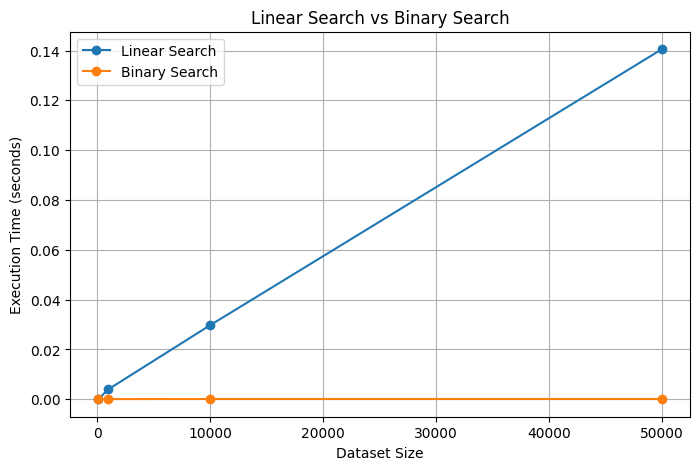

In [13]:
plt.figure(figsize=(8, 5))

for algorithm in ["Linear Search", "Binary Search"]:

    data = search_df[
        search_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (sec)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Dataset Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Linear Search vs Binary Search")
plt.legend()
plt.grid(True)

plt.show()

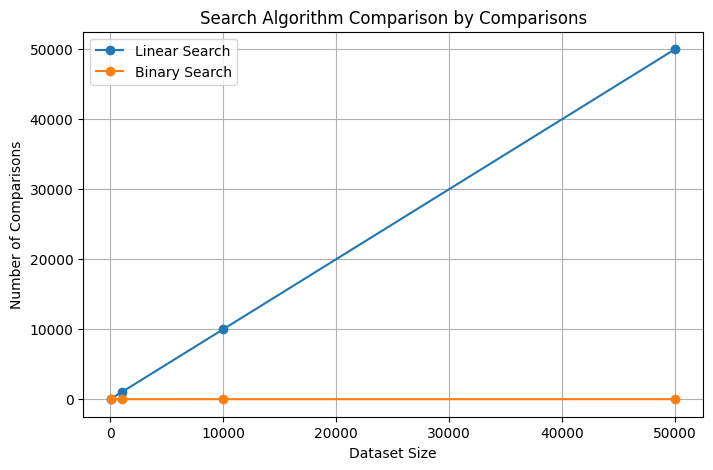

In [14]:
plt.figure(figsize=(8, 5))

for algorithm in ["Linear Search", "Binary Search"]:

    data = search_df[
        search_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Comparisons"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Dataset Size")
plt.ylabel("Number of Comparisons")
plt.title("Search Algorithm Comparison by Comparisons")
plt.legend()
plt.grid(True)

plt.show()

# 2. Factorial Algorithm Analysis

Two factorial implementations are analyzed:

- Recursive Factorial
- Iterative Factorial

The required input sizes are:

100, 500, and 1000.

The recursion limit is increased to allow the recursive implementation
to execute for n = 1000.

In [15]:
factorial_sizes = [100, 500, 1000]

factorial_results = []

for n in factorial_sizes:

    print("Testing factorial n =", n)

    # Recursive Factorial
    recursive = measure_function(
        recursive_factorial,
        n
    )

    factorial_results.append({
        "Algorithm": "Recursive Factorial",
        "Input Size": n,
        "Execution Time (sec)": recursive["time_sec"],
        "Memory (KB)": recursive["memory_kb"]
    })

    # Iterative Factorial
    iterative = measure_function(
        iterative_factorial,
        n
    )

    factorial_results.append({
        "Algorithm": "Iterative Factorial",
        "Input Size": n,
        "Execution Time (sec)": iterative["time_sec"],
        "Memory (KB)": iterative["memory_kb"]
    })

factorial_df = pd.DataFrame(factorial_results)

factorial_df

Testing factorial n = 100
Testing factorial n = 500
Testing factorial n = 1000


,Algorithm,Input Size,Execution Time (sec),Memory (KB)
0,Recursive Factorial,100,0.000221,0.195312
1,Iterative Factorial,100,0.000082,0.234375
2,Recursive Factorial,500,0.002578,8.089844
3,Iterative Factorial,500,0.001289,1.776367
4,Recursive Factorial,1000,0.012708,25.741211
5,Iterative Factorial,1000,0.001640,2.343750


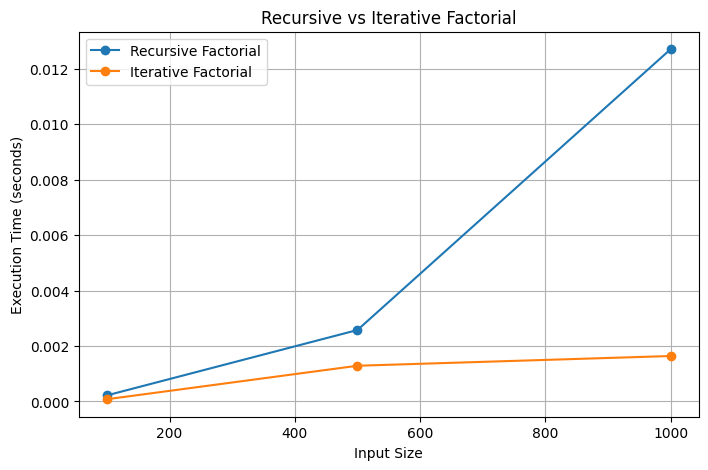

In [16]:
plt.figure(figsize=(8, 5))

for algorithm in [
    "Recursive Factorial",
    "Iterative Factorial"
]:

    data = factorial_df[
        factorial_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (sec)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Recursive vs Iterative Factorial")
plt.legend()
plt.grid(True)

plt.show()

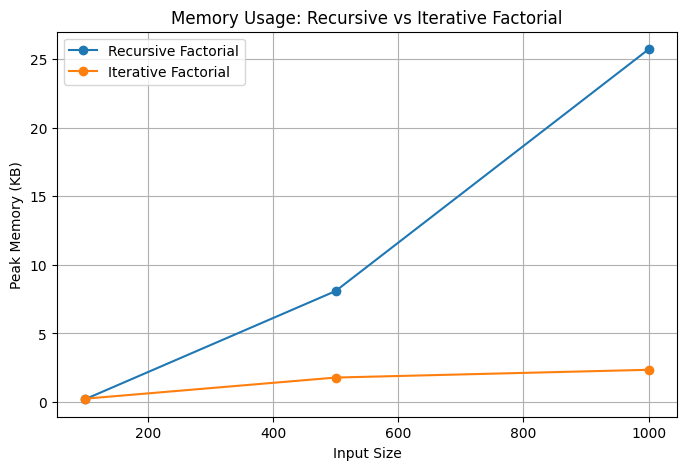

In [17]:
plt.figure(figsize=(8, 5))

for algorithm in [
    "Recursive Factorial",
    "Iterative Factorial"
]:

    data = factorial_df[
        factorial_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Memory (KB)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Peak Memory (KB)")
plt.title("Memory Usage: Recursive vs Iterative Factorial")
plt.legend()
plt.grid(True)

plt.show()

# 3. Loop Algorithm Analysis

Two loop-based algorithms are analyzed:

- Single Loop Traversal
- Nested Loop Traversal

The required input sizes are:

100, 1000, 10000, and 50000.

### Safe Benchmarking Strategy

A single loop performs approximately n operations.

A nested loop performs approximately n² operations.

Running the nested loop for n = 10000 would require:

10000² = 100,000,000 operations.

Running it for n = 50000 would require:

50000² = 2,500,000,000 operations.

Therefore, the nested loop is actually benchmarked only for
n = 100 and n = 1000.

For n = 10000 and n = 50000, the operation count is calculated
mathematically instead of executing billions of operations.

This prevents unnecessary CPU load while still demonstrating the
O(n²) growth required by the assignment.

In [20]:
loop_sizes = [100, 1000, 10000, 50000]

loop_results = []

for n in loop_sizes:

    # -----------------------------
    # Single Loop
    # -----------------------------
    single = measure_function(
        single_loop,
        n
    )

    loop_results.append({
        "Algorithm": "Single Loop Traversal",
        "Input Size": n,
        "Operations": single["result"],
        "Execution Time (sec)": single["time_sec"],
        "Memory (KB)": single["memory_kb"],
        "Measurement": "Measured"
    })

    # -----------------------------
    # Nested Loop
    # -----------------------------
    if n <= 1000:

        nested = measure_function(
            nested_loop,
            n
        )

        loop_results.append({
            "Algorithm": "Nested Loop Traversal",
            "Input Size": n,
            "Operations": nested["result"],
            "Execution Time (sec)": nested["time_sec"],
            "Memory (KB)": nested["memory_kb"],
            "Measurement": "Measured"
        })

    else:

        # DO NOT execute nested_loop(n)
        # Calculate operation count directly.
        operations = n * n

        loop_results.append({
            "Algorithm": "Nested Loop Traversal",
            "Input Size": n,
            "Operations": operations,
            "Execution Time (sec)": None,
            "Memory (KB)": None,
            "Measurement": "Theoretical"
        })

loop_df = pd.DataFrame(loop_results)

loop_df

,Algorithm,Input Size,Operations,Execution Time (sec),Memory (KB),Measurement
0,Single Loop Traversal,100,100,0.000018,0.085938,Measured
1,Nested Loop Traversal,100,10000,0.009677,1.712891,Measured
2,Single Loop Traversal,1000,1000,0.001029,0.132812,Measured
3,Nested Loop Traversal,1000,1000000,1.611210,0.331055,Measured
4,Single Loop Traversal,10000,10000,0.013119,0.132812,Measured
5,Nested Loop Traversal,10000,100000000,NaN,NaN,Theoretical
6,Single Loop Traversal,50000,50000,0.065891,0.132812,Measured
7,Nested Loop Traversal,50000,2500000000,NaN,NaN,Theoretical


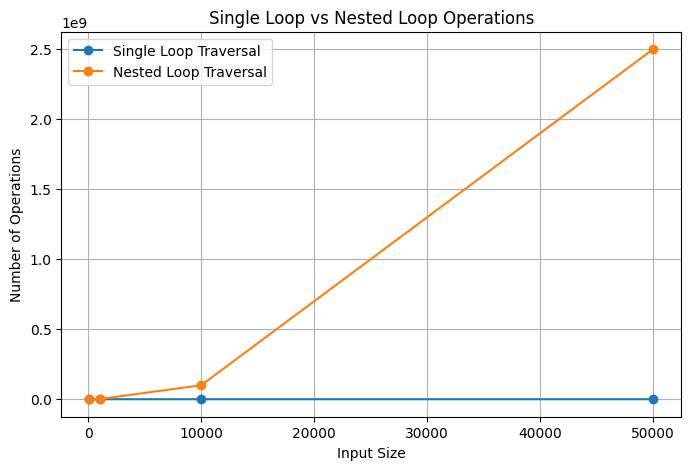

In [21]:
plt.figure(figsize=(8, 5))

for algorithm in [
    "Single Loop Traversal",
    "Nested Loop Traversal"
]:

    data = loop_df[
        loop_df["Algorithm"] == algorithm
    ]

    plt.plot(
        data["Input Size"],
        data["Operations"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Number of Operations")
plt.title("Single Loop vs Nested Loop Operations")
plt.legend()
plt.grid(True)

plt.show()

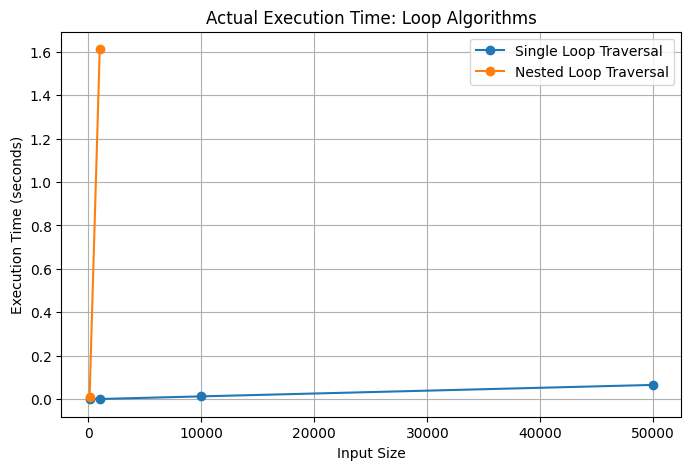

In [22]:
plt.figure(figsize=(8, 5))

for algorithm in [
    "Single Loop Traversal",
    "Nested Loop Traversal"
]:

    data = loop_df[
        (loop_df["Algorithm"] == algorithm) &
        (loop_df["Execution Time (sec)"].notna())
    ]

    plt.plot(
        data["Input Size"],
        data["Execution Time (sec)"],
        marker="o",
        label=algorithm
    )

plt.xlabel("Input Size")
plt.ylabel("Execution Time (seconds)")
plt.title("Actual Execution Time: Loop Algorithms")
plt.legend()
plt.grid(True)

plt.show()

# 4. Complexity Analysis

| Algorithm | Time Complexity | Space Complexity |
|---|---|---|
| Linear Search | O(n) | O(1) |
| Binary Search | O(log n) | O(1) |
| Recursive Factorial | O(n) | O(n) |
| Iterative Factorial | O(n) | O(1) |
| Single Loop Traversal | O(n) | O(1) |
| Nested Loop Traversal | O(n²) | O(1) |

The theoretical complexities help explain how the algorithms behave
as the input size increases.

complexity_df = pd.DataFrame({
    "Algorithm": [
        "Linear Search",
        "Binary Search",
        "Recursive Factorial",
        "Iterative Factorial",
        "Single Loop Traversal",
        "Nested Loop Traversal"
    ],
    "Time Complexity": [
        "O(n)",
        "O(log n)",
        "O(n)",
        "O(n)",
        "O(n)",
        "O(n²)"
    ],
    "Space Complexity": [
        "O(1)",
        "O(1)",
        "O(n)",
        "O(1)",
        "O(1)",
        "O(1)"
    ]
})

complexity_df

# 5. Comparative Study

## Linear Search vs Binary Search

Linear Search checks elements sequentially, so its number of comparisons
increases with the size of the dataset.

Binary Search repeatedly divides the search interval approximately in half.
Therefore, its number of comparisons grows logarithmically.

## Recursive vs Iterative Factorial

Both factorial implementations have O(n) time complexity.

The recursive implementation uses the function call stack, resulting in
O(n) additional space.

The iterative implementation uses a loop and requires O(1) additional
space.

## Single Loop vs Nested Loop

The Single Loop Traversal performs approximately n operations.

The Nested Loop Traversal performs approximately n² operations.

Therefore, the number of operations grows much faster for the nested
loop as the input size increases.

## Execution Time and Theoretical Complexity

Actual execution time can vary because of hardware, operating system
activity, Python interpreter overhead, and other factors.

Therefore, experimental results should be interpreted together with
theoretical complexity.

In [23]:
print("SEARCH RESULTS")
display(search_df)

print("\nFACTORIAL RESULTS")
display(factorial_df)

print("\nLOOP RESULTS")
display(loop_df)

SEARCH RESULTS


,Algorithm,Input Size,Result,Comparisons,Execution Time (sec),Memory (KB)
0,Linear Search,100,99,100,0.000033,0.085938
1,Binary Search,100,99,7,0.000007,0.000000
2,Linear Search,1000,999,1000,0.003993,0.144531
3,Binary Search,1000,999,10,0.000067,0.156250
4,Linear Search,10000,9999,10000,0.029689,0.144531
5,Binary Search,10000,9999,14,0.000091,0.156250
6,Linear Search,50000,49999,50000,0.140519,0.144531
7,Binary Search,50000,49999,16,0.000096,0.156250



FACTORIAL RESULTS


,Algorithm,Input Size,Execution Time (sec),Memory (KB)
0,Recursive Factorial,100,0.000221,0.195312
1,Iterative Factorial,100,0.000082,0.234375
2,Recursive Factorial,500,0.002578,8.089844
3,Iterative Factorial,500,0.001289,1.776367
4,Recursive Factorial,1000,0.012708,25.741211
5,Iterative Factorial,1000,0.001640,2.343750



LOOP RESULTS


,Algorithm,Input Size,Operations,Execution Time (sec),Memory (KB),Measurement
0,Single Loop Traversal,100,100,0.000018,0.085938,Measured
1,Nested Loop Traversal,100,10000,0.009677,1.712891,Measured
2,Single Loop Traversal,1000,1000,0.001029,0.132812,Measured
3,Nested Loop Traversal,1000,1000000,1.611210,0.331055,Measured
4,Single Loop Traversal,10000,10000,0.013119,0.132812,Measured
5,Nested Loop Traversal,10000,100000000,NaN,NaN,Theoretical
6,Single Loop Traversal,50000,50000,0.065891,0.132812,Measured
7,Nested Loop Traversal,50000,2500000000,NaN,NaN,Theoretical


# 6. Conclusion

The benchmarking experiments demonstrate how algorithm performance
changes with input size.

Linear Search requires an increasing number of comparisons as the
dataset grows, while Binary Search requires substantially fewer
comparisons.

Recursive and Iterative Factorial both have linear time complexity,
but recursion requires additional stack space.

Single Loop Traversal grows linearly with the input size, whereas
Nested Loop Traversal grows quadratically.

The experiments also demonstrate that theoretical complexity and
measured execution time should be considered together when evaluating
algorithm performance.

For large nested-loop inputs, theoretical operation counts were used
instead of executing billions of operations. This provides the required
complexity analysis without placing unnecessary computational load on
the system.